<a href="https://colab.research.google.com/github/sileysa/Semester_5/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Langkah 1 — Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Langkah 2 — Upload dan membaca dataset

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))
data = pd.read_csv(file_name)

print("Ukuran dataset:", data.shape)
print("\nLima data pertama:")
display(data.head())

print("\nNama kolom:")
print(data.columns.tolist())

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset (1).csv
Ukuran dataset: (660, 7)

Lima data pertama:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3



Nama kolom:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


# Langkah 3 — Memeriksa kondisi dataset

In [3]:
print("Informasi dataset:")
data.info()

print("\nJumlah missing value:")
print(data.isnull().sum())

print("\nStatistik deskriptif:")
display(data.describe())

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah missing value:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Statistik deskriptif:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


# Langkah 4 — Menyiapkan seluruh variabel yang dapat digunakan

In [4]:
# Membuat salinan dataset
df = data.copy()

# Menghapus spasi pada nama kolom
df.columns = df.columns.str.strip()

# Menghapus baris duplikat
df = df.drop_duplicates().reset_index(drop=True)

# Menentukan kolom identitas yang tidak digunakan
id_columns = [
    col for col in df.columns
    if col.lower().replace("_", " ").strip()
    in ["sl no", "customer key", "customer id", "customerid", "id"]
]

# Mengambil seluruh kolom numerik
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Menghapus kolom identitas dari fitur
feature_columns = [
    col for col in numeric_columns
    if col not in id_columns
]

# Menangani missing value pada fitur numerik
X_df = df[feature_columns].copy()
X_df = X_df.replace([np.inf, -np.inf], np.nan)

# Mengisi missing value menggunakan median masing-masing kolom
X_df = X_df.fillna(X_df.median())

print("Kolom identitas yang tidak digunakan:", id_columns)
print("\nFitur yang digunakan untuk clustering:")
print(feature_columns)

print("\nJumlah fitur:", len(feature_columns))
display(X_df.head())

Kolom identitas yang tidak digunakan: ['Sl_No', 'Customer Key']

Fitur yang digunakan untuk clustering:
['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Jumlah fitur: 5


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


# Langkah 5 — Normalisasi fitur

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_df)

print("Ukuran data setelah normalisasi:", X_scaled.shape)
print("Normalisasi berhasil!")

Ukuran data setelah normalisasi: (660, 5)
Normalisasi berhasil!


# Langkah 6 — Menentukan jumlah cluster

In [6]:
hasil_evaluasi = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)

    hasil_evaluasi.append({
        "Jumlah Cluster": k,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    })

evaluasi_df = pd.DataFrame(hasil_evaluasi)

display(evaluasi_df.round(4))

,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851
4,6,0.2268,1.4109
5,7,0.2163,1.4394
6,8,0.2187,1.4489
7,9,0.1953,1.5466
8,10,0.1931,1.5537


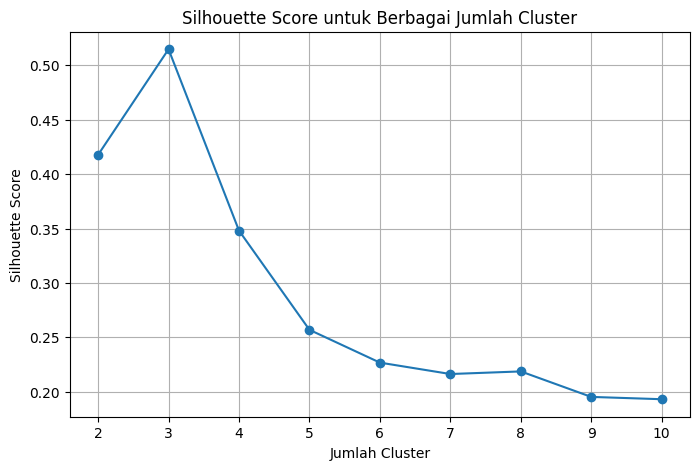

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    evaluasi_df["Jumlah Cluster"],
    evaluasi_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score untuk Berbagai Jumlah Cluster")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [8]:
best_k = int(
    evaluasi_df.loc[
        evaluasi_df["Silhouette Score"].idxmax(),
        "Jumlah Cluster"
    ]
)

print("Jumlah cluster terpilih:", best_k)

Jumlah cluster terpilih: 3


# Langkah 7 — Membuat model Agglomerative Clustering

In [9]:
agg = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

labels = agg.fit_predict(X_scaled)

# Menyimpan hasil cluster ke dalam dataset
data_hasil = df.copy()
data_hasil["Cluster"] = labels

print("Model Agglomerative Clustering berhasil dibuat!")
print("Jumlah cluster:", len(np.unique(labels)))

print("\nJumlah pelanggan pada setiap cluster:")
print(data_hasil["Cluster"].value_counts().sort_index())

Model Agglomerative Clustering berhasil dibuat!
Jumlah cluster: 3

Jumlah pelanggan pada setiap cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


# Langkah 8 — Membuat scatterplot

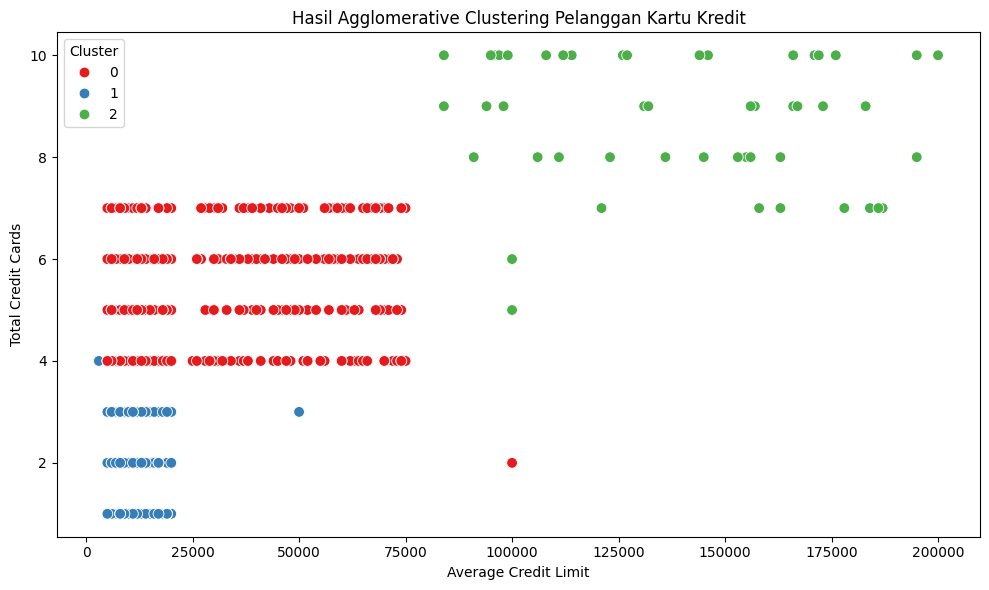

In [10]:
# Mencari nama kolom yang sesuai tanpa membedakan huruf besar/kecil
def cari_kolom(nama_target, daftar_kolom):
    target = nama_target.lower().replace("_", "").replace(" ", "")

    for kolom in daftar_kolom:
        nama = kolom.lower().replace("_", "").replace(" ", "")

        if nama == target:
            return kolom

    return None


col_x = cari_kolom("Avg_Credit_Limit", data_hasil.columns)

col_y = cari_kolom("Total_credit_card", data_hasil.columns)

# Mengakomodasi nama kolom yang umum digunakan dalam dataset kartu kredit
if col_y is None:
    col_y = cari_kolom("Total_Credit_Cards", data_hasil.columns)

if col_x is None or col_y is None:
    print("Kolom yang dibutuhkan tidak ditemukan.")
    print("Kolom tersedia:", data_hasil.columns.tolist())

else:
    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=data_hasil,
        x=col_x,
        y=col_y,
        hue="Cluster",
        palette="Set1",
        s=60
    )

    plt.title("Hasil Agglomerative Clustering Pelanggan Kartu Kredit")
    plt.xlabel("Average Credit Limit")
    plt.ylabel("Total Credit Cards")
    plt.legend(title="Cluster")
    plt.tight_layout()
    plt.show()

# Langkah 9 — Menghitung Silhouette Score dan DBI

In [11]:
sil_score = silhouette_score(X_scaled, labels)

dbi_score = davies_bouldin_score(X_scaled, labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index: {dbi_score:.4f}")

Silhouette Score: 0.5148
Davies-Bouldin Index: 0.6810


# Langkah 10 — Menyimpan hasil clustering

In [12]:
data_hasil.to_csv(
    "Hasil_Agglomerative_Clustering.csv",
    index=False
)

files.download("Hasil_Agglomerative_Clustering.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>